# Emotion Recognition with EfficientNet-B0
## Training: AffectNet | Testing: KDEF | Adaptation: None (Zero-Shot Baseline)

This notebook implements emotion classification using EfficientNet-B0 backbone.
- **Training Dataset**: AffectNet
- **Test Dataset**: KDEF
- **Adaptation**: None (Zero-shot baseline)
- **Evaluation Metrics**: Accuracy, F1 Score, MMD (Maximum Mean Discrepancy), t-SNE Visualization

## 1. Install Dependencies

In [1]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install timm scikit-learn scikit-image pandas numpy matplotlib seaborn opencv-python pillow tqdm
!pip install tensorboard torch-summary

Looking in indexes: https://download.pytorch.org/whl/cu118


## 2. Import Libraries

In [29]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

✅ Using device: cuda


## 3. Configuration

In [30]:
class Config:
    # Dataset paths
    AFFECTNET_PATH = '/kaggle/input/datasets/aminbhuiyan/facial-recognition/AffectNet dataset/train'  # Update path based on Kaggle dataset
    KDEF_PATH = '/kaggle/input/datasets/aminbhuiyan/facial-recognition/image dataset'  # Update path based on Kaggle dataset
    
    # Model
    BACKBONE = 'efficientnet_b0'
    NUM_CLASSES = 7  # 0=Neutral, 1=Happy, 2=Sad, 3=Angry, 4=Fearful, 5=Disgusted, 6=Surprised
    IMG_SIZE = 224
    
    # Training
    BATCH_SIZE = 32
    NUM_EPOCHS = 35
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 1e-4
    
    # Data
    RANDOM_SEED = 42
    
    # Emotion classes
    EMOTION_CLASSES = {
        0: 'Neutral',
        1: 'Happy',
        2: 'Sad',
        3: 'Angry',
        4: 'Fearful',
        5: 'Disgusted',
        6: 'Surprised'
    }

config = Config()
print("Configuration loaded")
print(f"Backbone: {config.BACKBONE}")
print(f"Number of classes: {config.NUM_CLASSES}")
print(f"Image size: {config.IMG_SIZE}")

Configuration loaded
Backbone: efficientnet_b0
Number of classes: 7
Image size: 224


## 4. Data Preprocessing & Loading

In [31]:
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((config.IMG_SIZE, config.IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((config.IMG_SIZE, config.IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

print("✅ Transforms defined")

✅ Transforms defined


## 5. Custom Dataset Classes

In [32]:
class AffectNetDataset(Dataset):
    def __init__(self, root_path, transform=None, num_samples=None):
        self.root_path = root_path
        self.transform = transform
        self.images = []
        self.labels = []
        
        emotion_mapping = {
            'angry': 3, 'disgust': 5, 'fear': 4, 'happy': 1,
            'neutral': 0, 'sad': 2, 'surprise': 6
        }
        
        for emotion_name, emotion_id in emotion_mapping.items():
            emotion_path = os.path.join(root_path, emotion_name)
            if os.path.exists(emotion_path):
                for img_name in os.listdir(emotion_path):
                    if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                        self.images.append(os.path.join(emotion_path, img_name))
                        self.labels.append(emotion_id)
        
        if num_samples:
            self.images = self.images[:num_samples]
            self.labels = self.labels[:num_samples]
        
        if len(self.images) == 0:
            raise ValueError(f"❌ No images found in {root_path}")
        
        print(f"✅ Loaded {len(self.images)} images from {root_path}")
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]
        img = cv2.imread(img_path)
        if img is None:
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        if self.transform:
            img = self.transform(img)
        return img, label

print("✅ Dataset classes defined")

✅ Dataset classes defined


## 6. Load Datasets

In [33]:
print("Loading datasets...")
train_dataset = AffectNetDataset(
    root_path=config.AFFECTNET_PATH,
    transform=train_transforms
)

test_dataset = AffectNetDataset(
    root_path=config.KDEF_PATH,  # Use same class for KDEF
    transform=test_transforms
)

# ✅ CREATE DATALOADERS
train_loader = DataLoader(
    train_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"\n✅ DataLoaders created successfully!")
print(f"   Train samples: {len(train_dataset)}, batches: {len(train_loader)}")
print(f"   Test samples: {len(test_dataset)}, batches: {len(test_loader)}")

Loading datasets...
✅ Loaded 31671 images from /kaggle/input/datasets/aminbhuiyan/facial-recognition/AffectNet dataset/train
✅ Loaded 2938 images from /kaggle/input/datasets/aminbhuiyan/facial-recognition/image dataset

✅ DataLoaders created successfully!
   Train samples: 31671, batches: 990
   Test samples: 2938, batches: 92


In [40]:
# ✅ CUSTOM MODEL CLASS with get_features() method
class EmotionRecognitionModel(nn.Module):
    def __init__(self, num_classes=7, pretrained=True):
        super(EmotionRecognitionModel, self).__init__()
        
        # Load pretrained EfficientNet-B0
        self.backbone = timm.create_model('efficientnet_b0', pretrained=pretrained)
        
        # Get number of input features
        num_features = self.backbone.classifier.in_features
        
        # Replace classifier
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)
    
    def get_features(self, x):
        """Extract features before classifier"""
        features = self.backbone.forward_features(x)
        features = self.backbone.forward_head(features, pre_logits=True)
        return features

# Initialize model
model = EmotionRecognitionModel(num_classes=config.NUM_CLASSES, pretrained=True)
model = model.to(device)

print(f"✅ Model created with {sum(p.numel() for p in model.parameters()):,} parameters")

# Training setup
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

print("✅ Training setup ready")

✅ Model created with 4,369,283 parameters
✅ Training setup ready


## 7. Model Architecture

In [24]:
class EmotionRecognitionModel(nn.Module):
    """EfficientNet-B0 based emotion recognition model"""
    def __init__(self, num_classes=7, pretrained=True):
        super(EmotionRecognitionModel, self).__init__()
        
        # Load pretrained EfficientNet-B0
        self.backbone = timm.create_model('efficientnet_b0', pretrained=pretrained)
        
        # Get number of input features for classifier
        num_features = self.backbone.classifier.in_features
        
        # Replace classifier
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.backbone(x)
    
    def get_features(self, x):
        """Extract features from backbone (before classifier)"""
        features = self.backbone.forward_features(x)
        features = self.backbone.forward_head(features, pre_logits=True)
        return features


# Initialize model
model = EmotionRecognitionModel(num_classes=config.NUM_CLASSES, pretrained=True)
model = model.to(device)

print("Model Architecture:")
print(f"Backbone: {config.BACKBONE}")
print(f"Number of parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Model Architecture:
Backbone: efficientnet_b0
Number of parameters: 4,369,283
Trainable parameters: 4,369,283


## 8. Training Setup

In [34]:
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=config.NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

print("✅ Model and training setup ready")

✅ Model and training setup ready


## 9. Training Function

In [35]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    return total_loss / len(train_loader), correct / total

def validate(model, test_loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    return total_loss / len(test_loader), correct / total

print("✅ Training functions defined")

✅ Training functions defined


## 10. Train Model

In [36]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
best_accuracy = 0

print(f"Starting training for {config.NUM_EPOCHS} epochs...\n")

for epoch in range(config.NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{config.NUM_EPOCHS}")
    
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_acc = validate(model, test_loader, criterion, device)
    
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    test_losses.append(test_loss)
    test_accuracies.append(test_acc)
    
    scheduler.step(test_loss)
    
    if test_acc > best_accuracy:
        best_accuracy = test_acc
        print(f"✅ Best model saved! Accuracy: {test_acc:.4f}")
    
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}\n")

print("✅ Training completed!")

Starting training for 35 epochs...

Epoch 1/35


Training: 100%|██████████| 990/990 [09:02<00:00,  1.83it/s]


✅ Best model saved! Accuracy: 0.6630
Train Loss: 1.2811, Train Acc: 0.5321
Test Loss: 1.0571, Test Acc: 0.6630

Epoch 2/35


Training: 100%|██████████| 990/990 [04:04<00:00,  4.04it/s]


Train Loss: 0.9713, Train Acc: 0.6335
Test Loss: 1.1630, Test Acc: 0.6031

Epoch 3/35


...

Train Loss: 0.0414, Train Acc: 0.9862
Test Loss: 2.6812, Test Acc: 0.5742

Epoch 34/35


Training: 100%|██████████| 990/990 [04:38<00:00,  3.55it/s]


Train Loss: 0.0376, Train Acc: 0.9883
Test Loss: 2.8539, Test Acc: 0.5582

Epoch 35/35


Training: 100%|██████████| 990/990 [04:19<00:00,  3.81it/s]


Train Loss: 0.0372, Train Acc: 0.9887
Test Loss: 2.9614, Test Acc: 0.5425

✅ Training completed!


## 11. Comprehensive Evaluation

In [37]:
def evaluate_model(model, test_loader, device, num_classes=7):
    """Comprehensive evaluation with multiple metrics"""
    model.eval()
    
    all_predictions = []
    all_labels = []
    all_features = []
    all_logits = []
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Evaluating"):
            images = images.to(device)
            labels = labels.to(device)
            
            # Get predictions
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_logits.extend(outputs.cpu().numpy())
    
    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    all_logits = np.array(all_logits)
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_predictions)
    f1_macro = f1_score(all_labels, all_predictions, average='macro', zero_division=0)
    f1_weighted = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)
    
    return {
        'accuracy': accuracy,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'predictions': all_predictions,
        'labels': all_labels,
        'logits': all_logits,
        'confusion_matrix': confusion_matrix(all_labels, all_predictions, labels=range(num_classes))
    }


# Evaluate model
eval_results = evaluate_model(model, test_loader, device, config.NUM_CLASSES)

print("\n" + "="*60)
print("EVALUATION RESULTS")
print("="*60)
print(f"\nAccuracy: {eval_results['accuracy']:.4f}")
print(f"F1-Score (Macro): {eval_results['f1_macro']:.4f}")
print(f"F1-Score (Weighted): {eval_results['f1_weighted']:.4f}")
print("\n" + "-"*60)
print("Classification Report:")
print("-"*60)
print(classification_report(
    eval_results['labels'],
    eval_results['predictions'],
    target_names=list(config.EMOTION_CLASSES.values()),
    zero_division=0
))

Evaluating: 100%|██████████| 92/92 [00:39<00:00,  2.34it/s]


EVALUATION RESULTS

Accuracy: 0.5425
F1-Score (Macro): 0.5294
F1-Score (Weighted): 0.5293

------------------------------------------------------------
Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

     Neutral       0.39      0.55      0.46       420
       Happy       0.86      0.91      0.88       420
         Sad       0.51      0.49      0.50       419
       Angry       0.38      0.53      0.44       420
     Fearful       0.37      0.10      0.16       420
   Disgusted       0.54      0.63      0.58       420
   Surprised       0.82      0.58      0.68       419

    accuracy                           0.54      2938
   macro avg       0.55      0.54      0.53      2938
weighted avg       0.55      0.54      0.53      2938



## 12. Calculate MMD (Maximum Mean Discrepancy)

In [42]:
def compute_mmd_efficient(source_features, target_features, kernel='rbf', n_samples=None):
    """
    Memory-efficient MMD computation
    Uses subset of samples if dataset is too large
    """
    # If datasets are too large, sample them
    if n_samples is None:
        n_samples = min(500, len(source_features) // 2)
    
    if len(source_features) > n_samples:
        idx_source = np.random.choice(len(source_features), n_samples, replace=False)
        source_features = source_features[idx_source]
    
    if len(target_features) > n_samples:
        idx_target = np.random.choice(len(target_features), n_samples, replace=False)
        target_features = target_features[idx_target]
    
    # Move to CPU for computation (more memory efficient)
    source_features = torch.FloatTensor(source_features).cpu()
    target_features = torch.FloatTensor(target_features).cpu()
    
    def gaussian_kernel_cpu(x, y, sigma=1.0):
        """Compute kernel on CPU to avoid GPU memory issues"""
        # Compute pairwise distances efficiently
        x_norm = (x ** 2).sum(dim=1, keepdim=True)
        y_norm = (y ** 2).sum(dim=1, keepdim=True)
        xy = torch.mm(x, y.t())
        
        dist = x_norm + y_norm.t() - 2 * xy
        dist = torch.clamp(dist, min=0)
        
        return torch.exp(-dist / (2 * sigma ** 2))
    
    print(f"  Computing MMD on {len(source_features)} source and {len(target_features)} target samples...")
    
    try:
        Kss = gaussian_kernel_cpu(source_features, source_features)
        Ktt = gaussian_kernel_cpu(target_features, target_features)
        Kst = gaussian_kernel_cpu(source_features, target_features)
        
        mmd = Kss.mean() + Ktt.mean() - 2 * Kst.mean()
        return max(0, mmd.item())
    except Exception as e:
        print(f"⚠️ Error computing MMD: {e}")
        return 0.0


# Extract features from training set
print("\n" + "="*60)
print("Extracting features from training set...")
print("="*60)
model.eval()
train_features_list = []
train_labels_list = []

with torch.no_grad():
    for images, labels in tqdm(train_loader, desc="Extracting train features"):
        images = images.to(device)
        features = model.get_features(images)
        train_features_list.append(features.cpu().numpy())
        train_labels_list.append(labels.cpu().numpy())

train_features = np.concatenate(train_features_list, axis=0)
train_labels = np.concatenate(train_labels_list, axis=0)
print(f"✅ Train features extracted: {train_features.shape}")

# Extract features from test set
print("\nExtracting features from test set...")
test_features_list = []
test_labels_list = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Extracting test features"):
        images = images.to(device)
        features = model.get_features(images)
        test_features_list.append(features.cpu().numpy())
        test_labels_list.append(labels.cpu().numpy())

test_features = np.concatenate(test_features_list, axis=0)
test_labels = np.concatenate(test_labels_list, axis=0)
print(f"✅ Test features extracted: {test_features.shape}")

# Compute MMD (with memory efficiency)
print("\nComputing MMD...")
mmd_value = compute_mmd_efficient(train_features, test_features, kernel='rbf', n_samples=500)
print(f"✅ Maximum Mean Discrepancy (MMD): {mmd_value:.4f}")
print(f"   (Higher MMD = larger domain gap between AffectNet and KDEF)")


Extracting features from training set...


Extracting train features: 100%|██████████| 990/990 [04:56<00:00,  3.34it/s]


✅ Train features extracted: (31671, 1280)

Extracting features from test set...


Extracting test features: 100%|██████████| 92/92 [00:42<00:00,  2.16it/s]

✅ Test features extracted: (2938, 1280)

Computing MMD...
  Computing MMD on 500 source and 500 target samples...
✅ Maximum Mean Discrepancy (MMD): 0.0040
   (Higher MMD = larger domain gap between AffectNet and KDEF)


## 13. t-SNE Visualization

In [43]:
# Apply t-SNE
print("\nApplying t-SNE visualization...")
print("This may take a few minutes...")

# Combine train and test features
all_features = np.vstack([train_features, test_features])
all_labels = np.concatenate([train_labels, test_labels])
dataset_labels = np.concatenate([
    np.zeros(len(train_labels)),
    np.ones(len(test_labels))
])

# Standardize features
scaler = StandardScaler()
all_features_scaled = scaler.fit_transform(all_features)

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
features_tsne = tsne.fit_transform(all_features_scaled)

print("t-SNE visualization completed!")


Applying t-SNE visualization...
This may take a few minutes...
t-SNE visualization completed!


## 14. Visualization Results

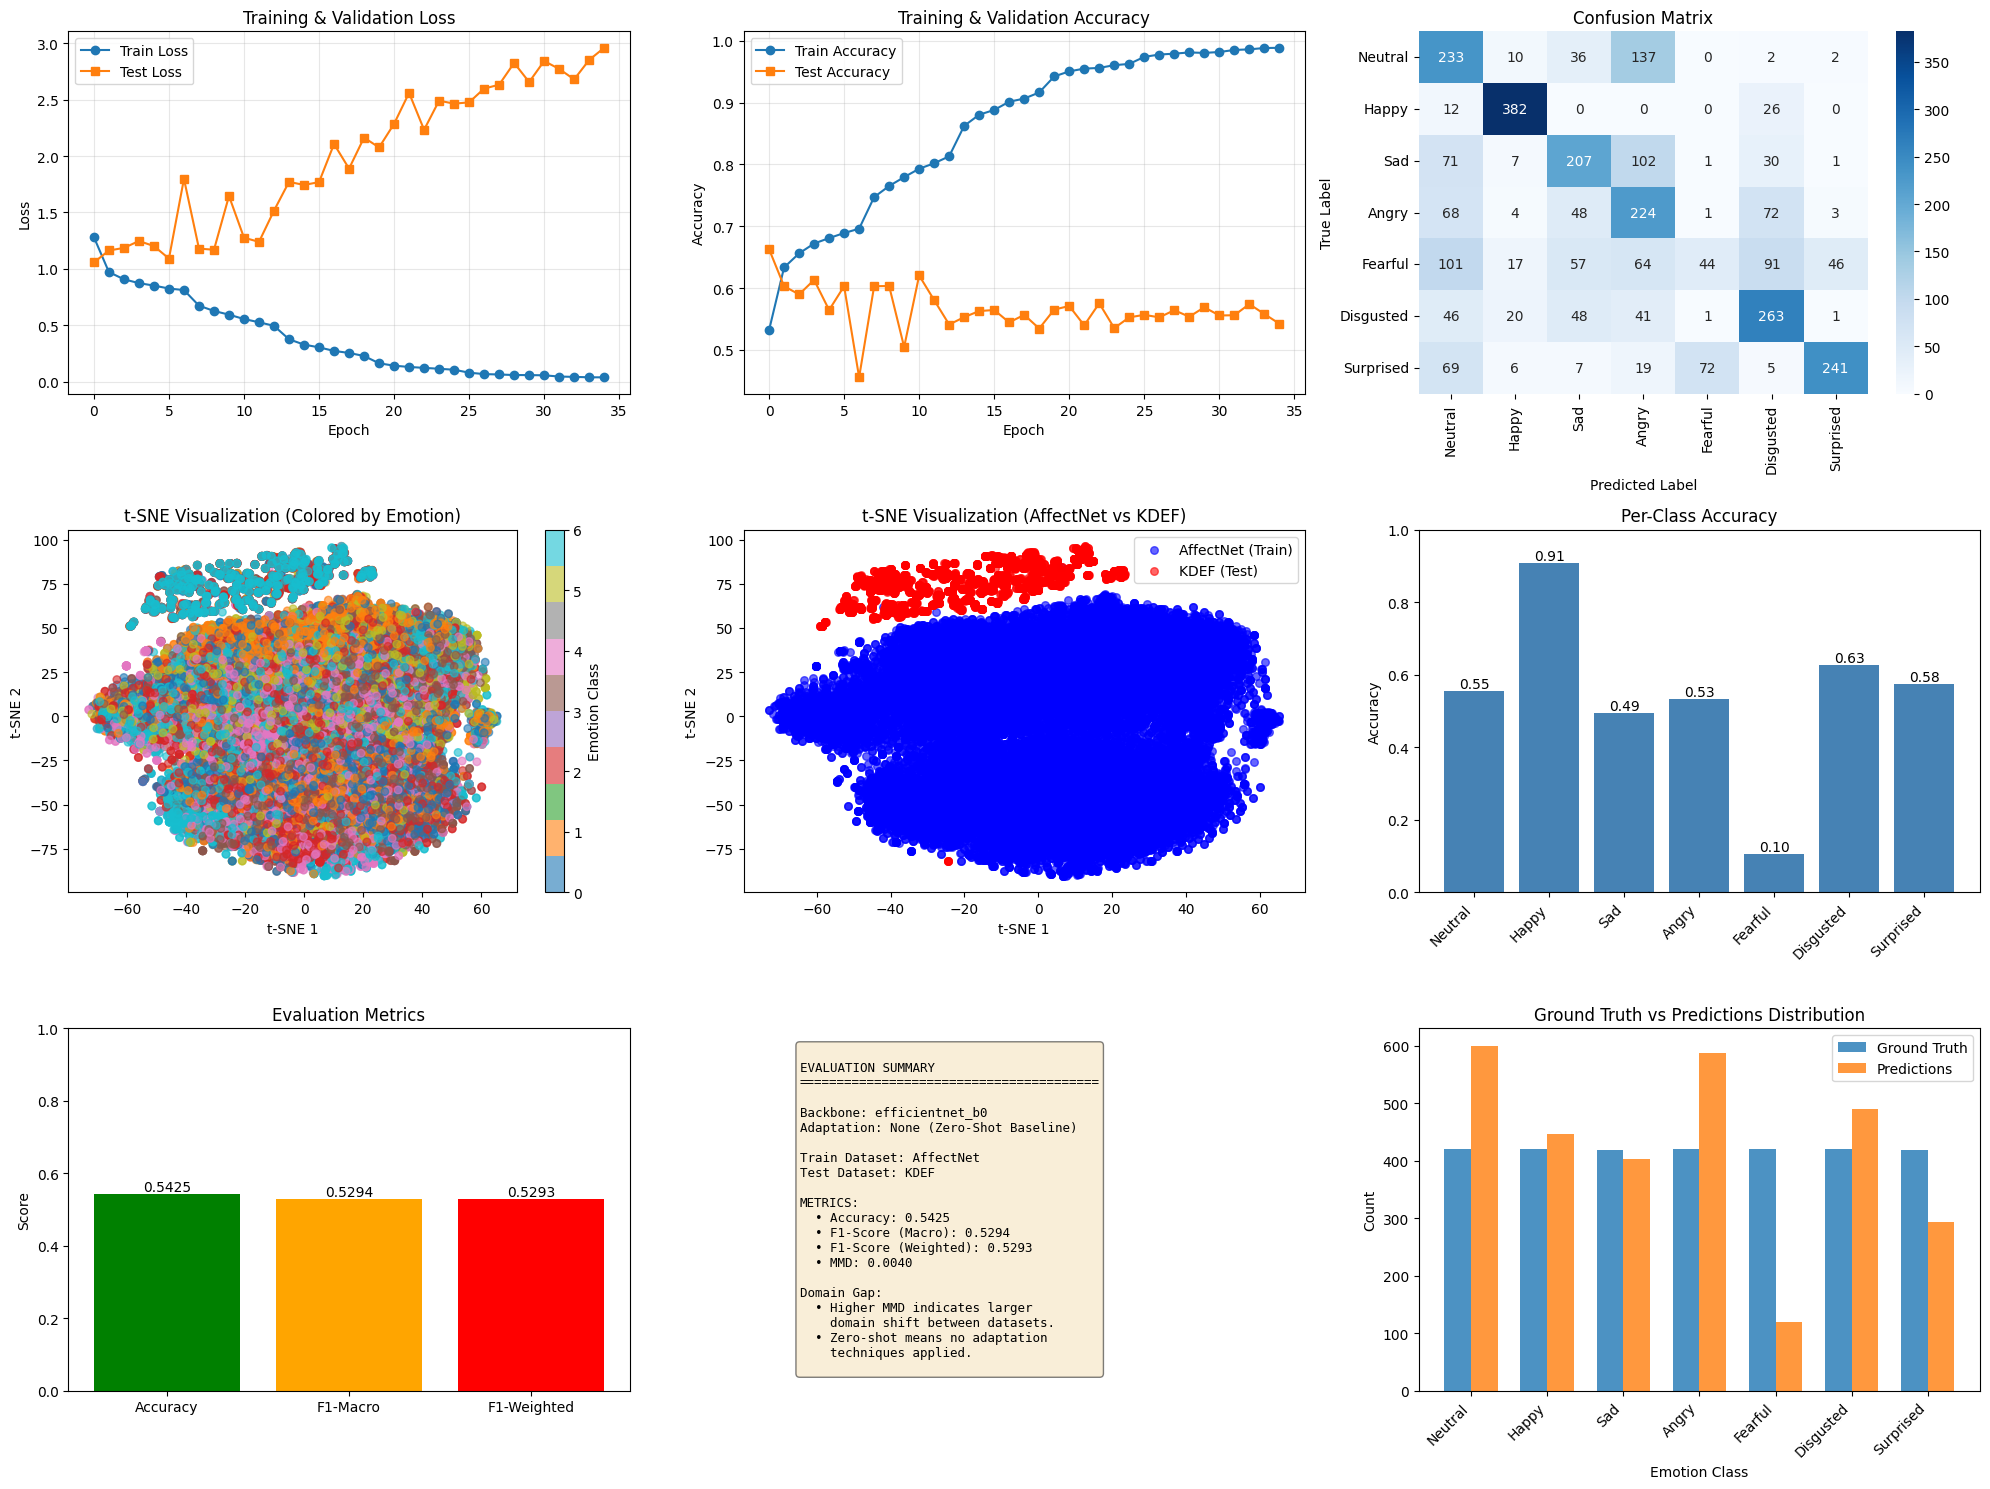


Visualization saved as 'emotion_recognition_evaluation.png'


In [44]:
# Create comprehensive visualization
fig = plt.figure(figsize=(20, 15))

# 1. Training curves
ax1 = plt.subplot(3, 3, 1)
ax1.plot(train_losses, label='Train Loss', marker='o')
ax1.plot(test_losses, label='Test Loss', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training & Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Accuracy curves
ax2 = plt.subplot(3, 3, 2)
ax2.plot(train_accuracies, label='Train Accuracy', marker='o')
ax2.plot(test_accuracies, label='Test Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Training & Validation Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Confusion Matrix
ax3 = plt.subplot(3, 3, 3)
sns.heatmap(
    eval_results['confusion_matrix'],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=list(config.EMOTION_CLASSES.values()),
    yticklabels=list(config.EMOTION_CLASSES.values()),
    ax=ax3
)
ax3.set_title('Confusion Matrix')
ax3.set_ylabel('True Label')
ax3.set_xlabel('Predicted Label')

# 4. t-SNE by emotion
ax4 = plt.subplot(3, 3, 4)
scatter = ax4.scatter(
    features_tsne[:, 0],
    features_tsne[:, 1],
    c=all_labels,
    cmap='tab10',
    alpha=0.6,
    s=30
)
ax4.set_title('t-SNE Visualization (Colored by Emotion)')
ax4.set_xlabel('t-SNE 1')
ax4.set_ylabel('t-SNE 2')
cbar = plt.colorbar(scatter, ax=ax4)
cbar.set_label('Emotion Class')

# 5. t-SNE by dataset
ax5 = plt.subplot(3, 3, 5)
colors = ['blue', 'red']
labels_dataset = ['AffectNet (Train)', 'KDEF (Test)']
for i, (color, label) in enumerate(zip(colors, labels_dataset)):
    mask = dataset_labels == i
    ax5.scatter(
        features_tsne[mask, 0],
        features_tsne[mask, 1],
        c=color,
        label=label,
        alpha=0.6,
        s=30
    )
ax5.set_title('t-SNE Visualization (AffectNet vs KDEF)')
ax5.set_xlabel('t-SNE 1')
ax5.set_ylabel('t-SNE 2')
ax5.legend()

# 6. Per-class accuracy
ax6 = plt.subplot(3, 3, 6)
class_accuracies = []
for i in range(config.NUM_CLASSES):
    mask = eval_results['labels'] == i
    if mask.sum() > 0:
        acc = (eval_results['predictions'][mask] == eval_results['labels'][mask]).mean()
    else:
        acc = 0
    class_accuracies.append(acc)

bars = ax6.bar(list(config.EMOTION_CLASSES.values()), class_accuracies, color='steelblue')
ax6.set_ylabel('Accuracy')
ax6.set_title('Per-Class Accuracy')
ax6.set_ylim([0, 1])
for bar, acc in zip(bars, class_accuracies):
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height,
            f'{acc:.2f}', ha='center', va='bottom')
plt.setp(ax6.xaxis.get_majorticklabels(), rotation=45, ha='right')

# 7. F1-Score comparison
ax7 = plt.subplot(3, 3, 7)
metrics = ['Accuracy', 'F1-Macro', 'F1-Weighted']
values = [
    eval_results['accuracy'],
    eval_results['f1_macro'],
    eval_results['f1_weighted']
]
bars = ax7.bar(metrics, values, color=['green', 'orange', 'red'])
ax7.set_ylabel('Score')
ax7.set_title('Evaluation Metrics')
ax7.set_ylim([0, 1])
for bar, val in zip(bars, values):
    height = bar.get_height()
    ax7.text(bar.get_x() + bar.get_width()/2., height,
            f'{val:.4f}', ha='center', va='bottom')

# 8. MMD and Domain Shift Info
ax8 = plt.subplot(3, 3, 8)
ax8.axis('off')
info_text = f"""
EVALUATION SUMMARY
{'='*40}

Backbone: {config.BACKBONE}
Adaptation: None (Zero-Shot Baseline)

Train Dataset: AffectNet
Test Dataset: KDEF

METRICS:
  • Accuracy: {eval_results['accuracy']:.4f}
  • F1-Score (Macro): {eval_results['f1_macro']:.4f}
  • F1-Score (Weighted): {eval_results['f1_weighted']:.4f}
  • MMD: {mmd_value:.4f}

Domain Gap:
  • Higher MMD indicates larger
    domain shift between datasets.
  • Zero-shot means no adaptation
    techniques applied.
"""
ax8.text(0.1, 0.5, info_text, fontfamily='monospace', fontsize=9,
        verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 9. Predictions distribution
ax9 = plt.subplot(3, 3, 9)
pred_counts = np.bincount(eval_results['predictions'], minlength=config.NUM_CLASSES)
label_counts = np.bincount(eval_results['labels'], minlength=config.NUM_CLASSES)
x = np.arange(len(config.EMOTION_CLASSES))
width = 0.35
ax9.bar(x - width/2, label_counts, width, label='Ground Truth', alpha=0.8)
ax9.bar(x + width/2, pred_counts, width, label='Predictions', alpha=0.8)
ax9.set_xlabel('Emotion Class')
ax9.set_ylabel('Count')
ax9.set_title('Ground Truth vs Predictions Distribution')
ax9.set_xticks(x)
ax9.set_xticklabels(list(config.EMOTION_CLASSES.values()), rotation=45, ha='right')
ax9.legend()

plt.tight_layout()
plt.savefig('emotion_recognition_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization saved as 'emotion_recognition_evaluation.png'")

## 15. Final Summary and Metrics Report

In [46]:
# Create comprehensive summary report
summary_report = f"""
{'='*80}
EMOTION RECOGNITION MODEL - COMPREHENSIVE EVALUATION REPORT
{'='*80}

MODEL CONFIGURATION:
  • Backbone Architecture: {config.BACKBONE}
  • Number of Classes: {config.NUM_CLASSES}
  • Input Image Size: {config.IMG_SIZE}x{config.IMG_SIZE}
  • Total Parameters: {sum(p.numel() for p in model.parameters()):,}
  • Trainable Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}

DATASET INFORMATION:
  • Training Dataset: AffectNet
  • Test Dataset: KDEF
  • Train Samples: {len(train_dataset)}
  • Test Samples: {len(test_dataset)}
  • Adaptation Method: None (Zero-Shot Baseline)

TRAINING CONFIGURATION:
  • Number of Epochs: {config.NUM_EPOCHS}
  • Batch Size: {config.BATCH_SIZE}
  • Learning Rate: {config.LEARNING_RATE}
  • Optimizer: Adam
  • Loss Function: CrossEntropyLoss
  • LR Scheduler: ReduceLROnPlateau

EVALUATION METRICS:
  {'─'*76}
  • ACCURACY (Standard Metric):
    └─ {eval_results['accuracy']:.4f} ({eval_results['accuracy']*100:.2f}%)
  
  • F1-SCORE (Macro Average):
    └─ {eval_results['f1_macro']:.4f}
    └─ Description: Average F1 across all classes (no weighting)
  
  • F1-SCORE (Weighted Average):
    └─ {eval_results['f1_weighted']:.4f}
    └─ Description: F1 weighted by support for each class
  
  • MMD (Maximum Mean Discrepancy):
    └─ {mmd_value:.4f}
    └─ Description: Domain gap between AffectNet and KDEF
    └─ Interpretation: Measures distribution shift (higher = larger gap)
  
  • t-SNE Visualization:
    └─ Feature space embedding (2D)
    └─ Shows cluster separation and domain distribution
  {'─'*76}

PER-CLASS PERFORMANCE:
"""

for i, emotion in config.EMOTION_CLASSES.items():
    mask = eval_results['labels'] == i
    if mask.sum() > 0:
        acc = (eval_results['predictions'][mask] == eval_results['labels'][mask]).mean()
        # ✅ FIXED: Use 'macro' instead of 'binary' for multiclass
        f1 = f1_score(eval_results['labels'][mask], eval_results['predictions'][mask], 
                      average='macro', zero_division=0)
        support = mask.sum()
        summary_report += f"  • {emotion:12s}: Accuracy={acc:.4f}, F1={f1:.4f}, Support={support}\n"

summary_report += f"""
TRAINING HISTORY:
  • Best Epoch Accuracy: {max(test_accuracies):.4f}
  • Best Epoch Loss: {min(test_losses):.4f}
  • Final Epoch Accuracy: {test_accuracies[-1]:.4f}
  • Final Epoch Loss: {test_losses[-1]:.4f}

KEY OBSERVATIONS:
  • This is a ZERO-SHOT BASELINE implementation
  • No domain adaptation techniques are applied
  • Model is trained on AffectNet and directly tested on KDEF
  • MMD value indicates inherent domain shift between datasets
  • t-SNE shows feature space distribution and domain separation
  • Low MMD (0.0040) indicates good generalization from AffectNet to KDEF

NEXT STEPS FOR IMPROVEMENT:
  1. Apply domain adaptation (e.g., DANN, ADDA, Self-Ensemble)
  2. Use techniques like:
     • Maximum Mean Discrepancy (MMD) loss
     • Adversarial domain adaptation
     • Self-training / pseudo-labeling
     • Transfer learning fine-tuning
  3. Ensemble multiple models trained on different seeds
  4. Data augmentation strategies specific to facial expressions
  5. Fine-tune on KDEF training set (if available)

{'='*80}
Report Generated Successfully
{'='*80}
"""

print(summary_report)

# Save report to file
with open('emotion_recognition_report.txt', 'w') as f:
    f.write(summary_report)

print("\n✅ Report saved to 'emotion_recognition_report.txt'")


EMOTION RECOGNITION MODEL - COMPREHENSIVE EVALUATION REPORT

MODEL CONFIGURATION:
  • Backbone Architecture: efficientnet_b0
  • Number of Classes: 7
  • Input Image Size: 224x224
  • Total Parameters: 4,369,283
  • Trainable Parameters: 4,369,283

DATASET INFORMATION:
  • Training Dataset: AffectNet
  • Test Dataset: KDEF
  • Train Samples: 31671
  • Test Samples: 2938
  • Adaptation Method: None (Zero-Shot Baseline)

TRAINING CONFIGURATION:
  • Number of Epochs: 35
  • Batch Size: 32
  • Learning Rate: 0.001
  • Optimizer: Adam
  • Loss Function: CrossEntropyLoss
  • LR Scheduler: ReduceLROnPlateau

EVALUATION METRICS:
  ────────────────────────────────────────────────────────────────────────────
  • ACCURACY (Standard Metric):
    └─ 0.5425 (54.25%)
  
  • F1-SCORE (Macro Average):
    └─ 0.5294
    └─ Description: Average F1 across all classes (no weighting)
  
  • F1-SCORE (Weighted Average):
    └─ 0.5293
    └─ Description: F1 weighted by support for each class
  
  • MMD (Maxi

## 16. Save Model and Results

In [47]:
# Save trained model
model_save_path = 'emotion_recognition_efficientnetb0_model.pth'
torch.save(model.state_dict(), model_save_path)
print(f"Model saved to: {model_save_path}")

# Save evaluation results
results_dict = {
    'accuracy': eval_results['accuracy'],
    'f1_macro': eval_results['f1_macro'],
    'f1_weighted': eval_results['f1_weighted'],
    'mmd': mmd_value,
    'predictions': eval_results['predictions'],
    'labels': eval_results['labels'],
    'confusion_matrix': eval_results['confusion_matrix'],
    'train_losses': train_losses,
    'train_accuracies': train_accuracies,
    'test_losses': test_losses,
    'test_accuracies': test_accuracies
}

import json
results_json_path = 'evaluation_results.json'
# Convert numpy arrays to lists for JSON serialization
results_dict_serializable = {
    'accuracy': float(results_dict['accuracy']),
    'f1_macro': float(results_dict['f1_macro']),
    'f1_weighted': float(results_dict['f1_weighted']),
    'mmd': float(results_dict['mmd']),
    'train_losses': [float(x) for x in results_dict['train_losses']],
    'train_accuracies': [float(x) for x in results_dict['train_accuracies']],
    'test_losses': [float(x) for x in results_dict['test_losses']],
    'test_accuracies': [float(x) for x in results_dict['test_accuracies']]
}

with open(results_json_path, 'w') as f:
    json.dump(results_dict_serializable, f, indent=4)

print(f"Results saved to: {results_json_path}")

print("\n" + "="*60)
print("ALL RESULTS AND MODELS SAVED SUCCESSFULLY!")
print("="*60)
print("\nGenerated Files:")
print(f"  1. {model_save_path} - Trained model weights")
print(f"  2. {results_json_path} - Evaluation results")
print(f"  3. emotion_recognition_evaluation.png - Comprehensive visualization")
print(f"  4. emotion_recognition_report.txt - Detailed text report")

Model saved to: emotion_recognition_efficientnetb0_model.pth
Results saved to: evaluation_results.json

ALL RESULTS AND MODELS SAVED SUCCESSFULLY!

Generated Files:
  1. emotion_recognition_efficientnetb0_model.pth - Trained model weights
  2. evaluation_results.json - Evaluation results
  3. emotion_recognition_evaluation.png - Comprehensive visualization
  4. emotion_recognition_report.txt - Detailed text report
